# TEST for Bark







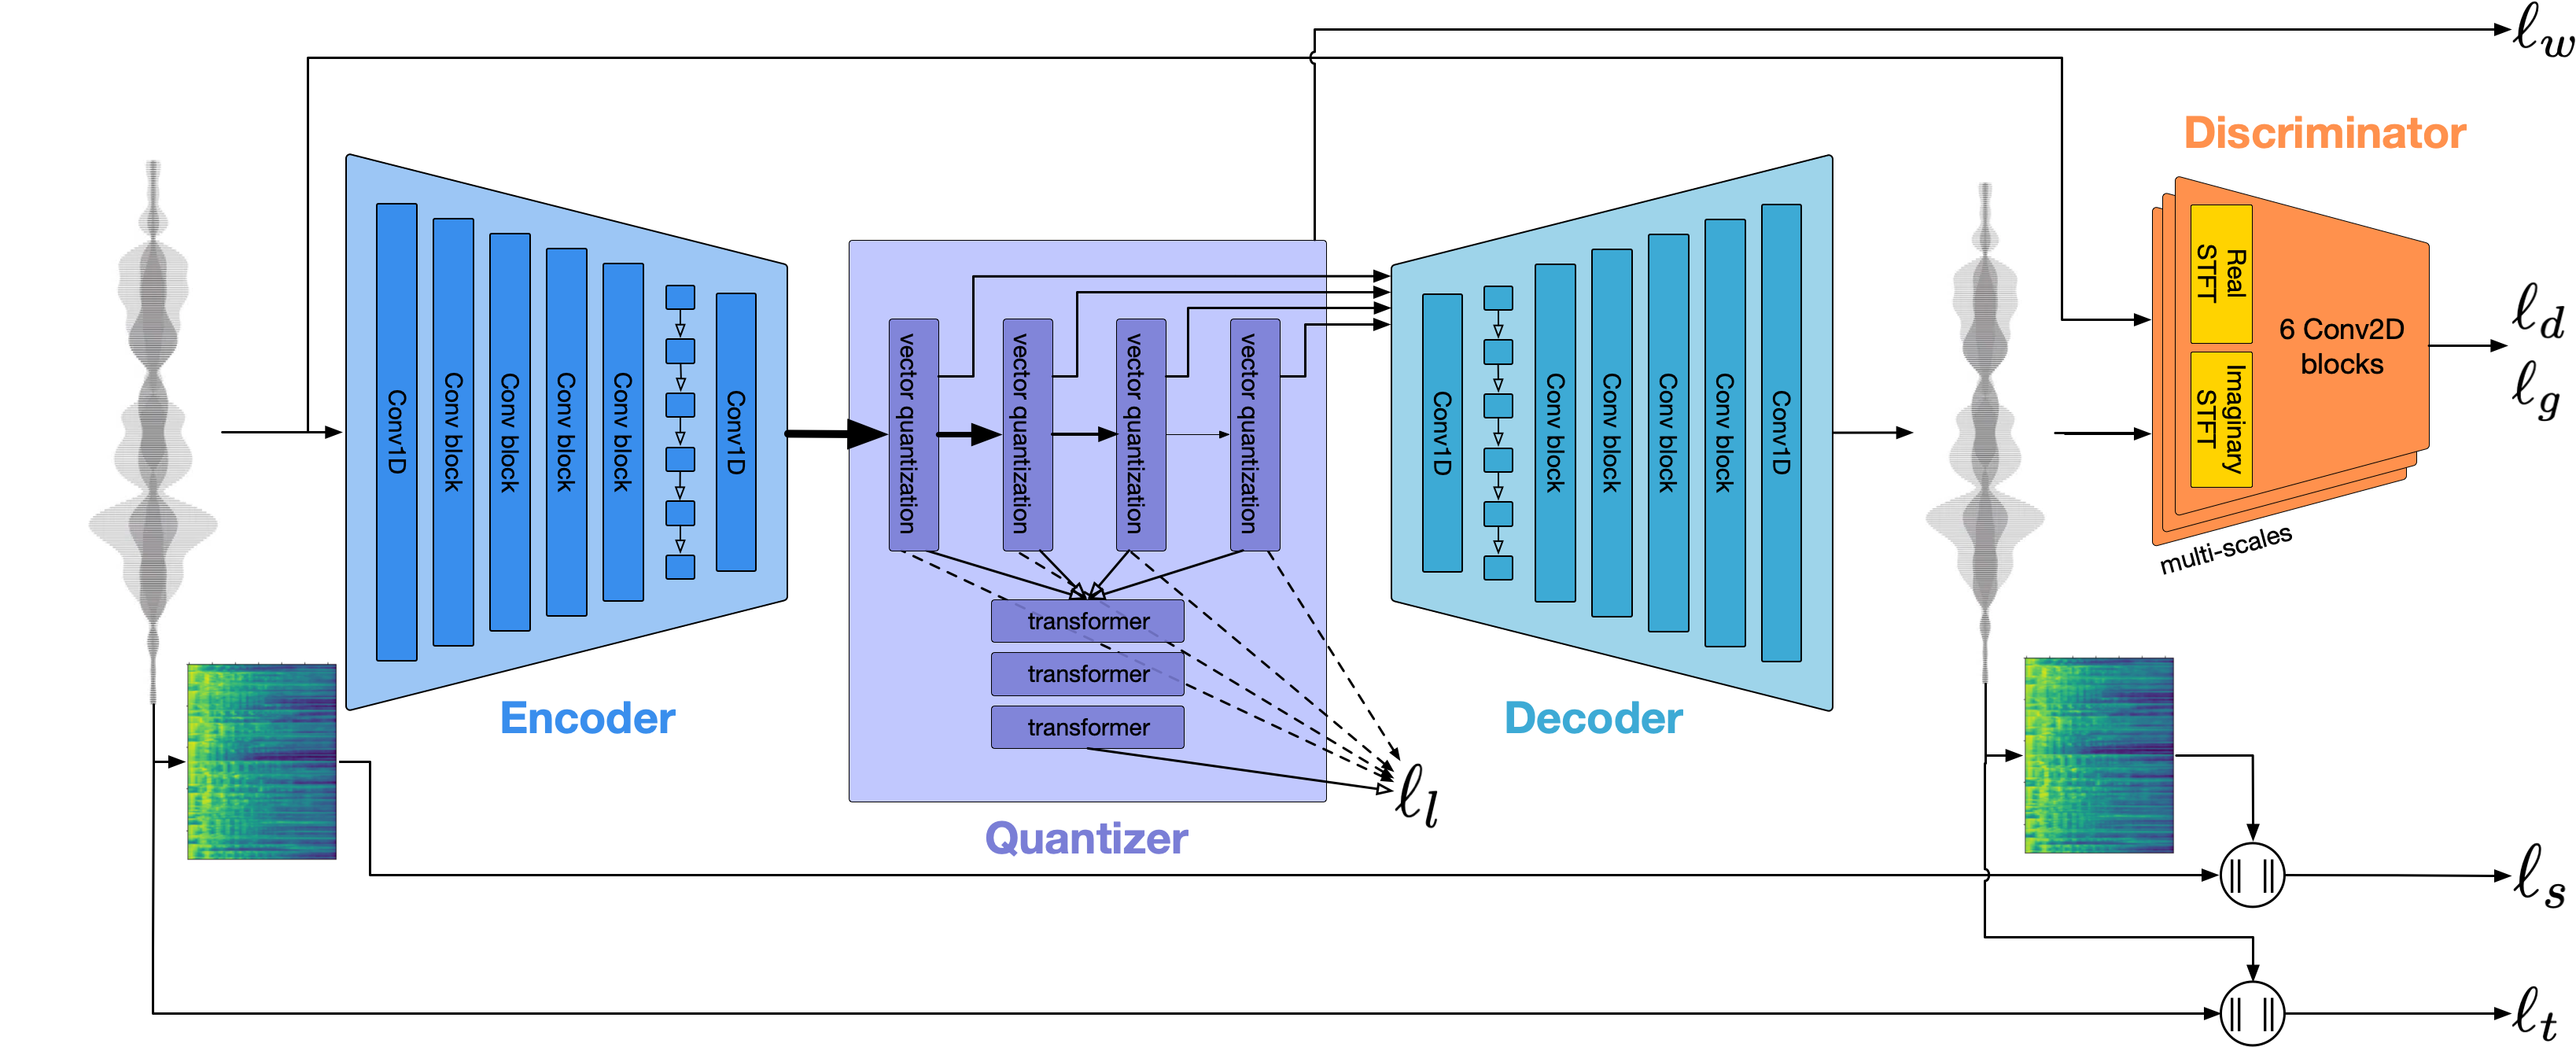

<b>Semantic model</b>
We look at Bark's semantic model, also called the text model. It is a GPT-2-like causal auto-regressive transformer model with a language modeling head on top. It takes in tokenized text (from a BERT tokenizer) as input and then predicts the semantic tokens that encode the audio to be generated.

It contains 80 million parameters and is implemented with the help of NanoGPT, a simple and blazing-fast library for setting up GPT-style models.

The output semantic tokens capture the meaning of the input text prompt and have a vocabulary size of 10,048 (i.e., the number of unique tokens the model can produce in its output).

<b>Coarse acoustics model</b>
The next model is the coarse acoustics model. It shares the same architecture as the semantic model, meaning it is a GPT-2-like causal autoregressive transformer with 80 million parameters.

It takes as input the semantic tokens from the semantic model and uses them to autoregressively predict the coarse acoustic tokens (aka token indices corresponding to the codebook) of the first two audio EnCodec codebooks.

These first two codebooks are considered coarse because they capture the coarser waveform characteristics.

<b>Fine acoustics model</b>
The final model is the fine acoustics model, a non-causal GPT-like autoencoder transformer with 80 million parameters.

It takes as input the predicted tokens for the first two codebooks generated by the coarse model and iteratively predicts the tokens of the last six codebooks based on the sum of the previous codebook embeddings.

These last six codebooks are considered fine because they capture the finer waveform characteristics.

Ultimately, we are dealing with eight codebooks in total, each with an embedding size of 1,024 (i.e., 1,024 codewords). Once the acoustic tokens have been predicted for all eight codebooks, they are input into the decoder to synthesize an output audio waveform.

The coarse and fine models aim to predict what semantic information should sound like in the domain of quantized acoustic tokens.

# Setup
Run everything in this section before any generation

**Models are located here:**
<font color='red'>Mac: ~/.cache/suno/bark_v0</font>
<font color='red'>Windows: %USERPROFILE%\.cache\suno\bark_v0</font>

**Voice prompts are located here**
<font color='red'>Bark/Bark_env/lib/python3.13/site-packages/bark/assets/prompts</font>

In [1]:
from importlib.metadata import PackageNotFoundError, version

try:
    current_version = version("setuptools")
except PackageNotFoundError:
    current_version = None

needs_install = current_version is None or tuple(int(part) for part in current_version.split(".")[:2]) >= (82, 0)

if needs_install:
    import subprocess
    import sys

    subprocess.check_call([sys.executable, "-m", "pip", "install", "setuptools<82"])
else:
    print(f"setuptools {current_version} already satisfies <82")

setuptools 80.10.2 already satisfies <82


In [2]:
from importlib import metadata
import torch, warnings, logging

has_mps = hasattr(torch.backends, "mps") and torch.backends.mps.is_available()
print("mps " + str(has_mps))

installed_packages_list = sorted([
    f"{dist.metadata.get('Name', dist.metadata.get('Summary', 'unknown')).lower()}=={dist.version}"
    for dist in metadata.distributions()
    if dist.metadata.get('Name')
])
print(installed_packages_list)

warnings.filterwarnings("ignore", category=UserWarning)
logging.getLogger("transformers").setLevel(logging.ERROR)
try:
    from transformers.utils import logging as transformers_logging
    transformers_logging.set_verbosity_error()
except Exception:
    pass

device = "cuda" if torch.cuda.is_available() else ("mps" if has_mps else "cpu")
if not has_mps and not hasattr(torch, "mps"):
    class _NoOpMPS:
        @staticmethod
        def empty_cache():
            return None

    torch.mps = _NoOpMPS()

print("selected device " + device)
#device = "cuda" - "cpu" - "cuda:0" - "mps"

mps False
['annotated-doc==0.0.5', 'anyio==4.15.1', 'argon2-cffi-bindings==26.1.0', 'argon2-cffi==25.1.0', 'arrow==1.4.0', 'asttokens==3.0.2', 'async-lru==2.4.0', 'attrs==26.1.0', 'babel==2.18.0', 'beautifulsoup4==4.15.0', 'bleach==6.4.0', 'boto3==1.43.114', 'botocore==1.43.114', 'certifi==2026.7.22', 'cffi==2.1.1', 'charset-normalizer==3.5.2', 'click==8.5.0', 'colorama==0.4.6', 'comm==0.2.3', 'contourpy==1.4.0', 'cycler==0.12.1', 'debugpy==1.8.22', 'defusedxml==0.7.1', 'einops==0.8.2', 'encodec==0.1.1', 'executing==2.3.0', 'fastjsonschema==2.22.2', 'filelock==4.2.0', 'fonttools==4.67.0', 'fqdn==1.6.0', 'fsspec==2026.9.0', 'funcy==2.1', 'h11==0.16.0', 'hf-xet==1.7.0', 'httpcore2==2.13.1', 'httpcore==1.0.9', 'httpx2==2.13.1', 'httpx==0.28.1', 'huggingface_hub==2.2.0', 'idna==3.20', 'ipykernel==7.4.0', 'ipython==9.17.1', 'ipython_pygments_lexers==1.1.1', 'ipywidgets==8.1.9', 'isoduration==20.11.0', 'jedi==0.20.1', 'jinja2==3.1.6', 'jmespath==1.1.0', 'json5==0.17.3', 'jsonpointer==3.2.1',

W1017 17:04:09.869000 33644 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 4.49GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/806 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/4.91k [00:00<?, ?B/s]

...

speaker_embeddings/v2/en_speaker_6_coars(…): downloading bytes:           |  0.00B            

speaker_embeddings/v2/en_speaker_6_fine_(…): reconstructing file:   0%|          |  0.00B / 15.0kB            

speaker_embeddings/v2/en_speaker_6_fine_(…): downloading bytes:           |  0.00B            

Bark model device: cuda:0
Input device: cuda:0


RuntimeError: Cannot execute emptyCache() without MPS backend.

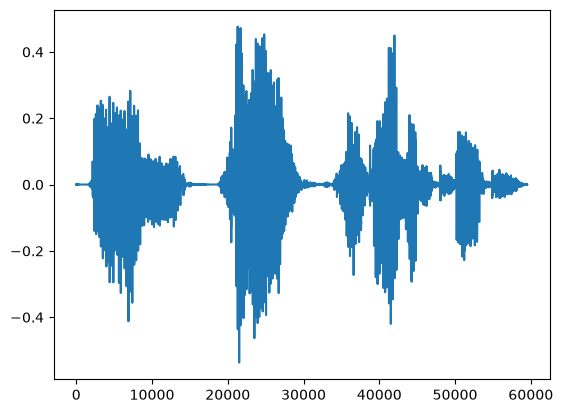

In [3]:
from transformers import AutoProcessor, BarkModel
from IPython.display import Audio
import matplotlib.pyplot as plt
import IPython.display as ipd
import gc, warnings

warnings.filterwarnings(
    "ignore",
    message=r".*Passing `generation_config` together with generation-related arguments=.*",
    module=r"transformers.*",
)

processor = AutoProcessor.from_pretrained("suno/bark")
model = BarkModel.from_pretrained("suno/bark").to(device)

voice_preset = "v2/en_speaker_6"
inputs = processor("Hello, my dog is cute", voice_preset=voice_preset).to(device)
print("Bark model device:", next(model.parameters()).device)
print("Input device:", inputs["input_ids"].device)

audio_array = model.generate(**inputs)
audio_array = audio_array.cpu().numpy().squeeze()
sample_rate = model.generation_config.sample_rate

def plot_and_hear(audio, sr):
    display(ipd.Audio(audio, rate=sr))
    plt.plot(audio)

plot_and_hear(audio_array, sample_rate)

torch.mps.empty_cache()
gc.collect()

Library of voices is here:
https://suno-ai.notion.site/8b8e8749ed514b0cbf3f699013548683?v=bc67cff786b04b50b3ceb756fd05f68c

List of some known non-speech sounds:
    [laughter]
    [laughs]
    [sighs]
    [music]
    [gasps]
    [clears throat]
    — or ... for hesitations
    ♪ for song lyrics
    capitalization for emphasis of a word
    MAN/WOMAN: for bias towards speaker

seed ====>10852335617005466459
Bark model device: cuda:0


speaker_embeddings/v2/en_speaker_3_seman(…): reconstructing file:   0%|          |  0.00B / 3.54kB            

speaker_embeddings/v2/en_speaker_3_seman(…): downloading bytes:           |  0.00B            

speaker_embeddings/v2/en_speaker_3_coars(…): reconstructing file:   0%|          |  0.00B / 10.4kB            

speaker_embeddings/v2/en_speaker_3_coars(…): downloading bytes:           |  0.00B            

speaker_embeddings/v2/en_speaker_3_fine_(…): reconstructing file:   0%|          |  0.00B / 20.6kB            

speaker_embeddings/v2/en_speaker_3_fine_(…): downloading bytes:           |  0.00B            

Input device: cuda:0
final audio_array shape: (11520,)
sample_rate: 24000


RuntimeError: Cannot execute emptyCache() without MPS backend.

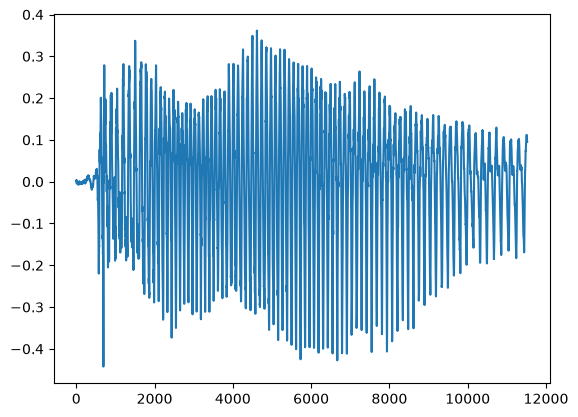

In [4]:
import gc
import random
import re
import warnings
import numpy as np
import torch

import matplotlib.pyplot as plt
import IPython.display as ipd

warnings.filterwarnings("ignore")

if 'processor' not in globals() or 'model' not in globals():
    raise RuntimeError("Run the earlier GPU Bark cell first so the model is already loaded.")

# Slower version kept for reference. Use this only if you want a longer sample and accept slower generation:
# long_string = "[clears throat] For a long time I used to go to bed early. Sometimes, when I had put out my candle, my eyes would close so quickly that I had not even time to say I'm going to sleep."

model.eval()
seeed = random.randrange(18446744073709551615)
print("seed ====>" + str(seeed))
print("Bark model device:", next(model.parameters()).device)

voice_preset = "v2/en_speaker_3"
test_string = "[clears throat] Hi."
inputs = processor(test_string, voice_preset=voice_preset).to(device)
print("Input device:", inputs["input_ids"].device)

with torch.inference_mode():
    audio_array = model.generate(**inputs, semantic_max_new_tokens=24)
audio_array = audio_array.cpu().numpy().squeeze()
audio_array_in = audio_array
sample_rate = model.generation_config.sample_rate
print("final audio_array shape:", audio_array.shape)
print("sample_rate:", sample_rate)
display(ipd.Audio(audio_array, rate=sample_rate))
plt.plot(audio_array)

torch.mps.empty_cache()
gc.collect()

**Save file:**

In [5]:
from scipy.io import wavfile
from typing import Dict, Optional, Union
import numpy as np
import torch
import bark.generation as bark_generation

bark_generation.GLOBAL_ENABLE_MPS = True

_original_torch_load = torch.load
def _patched_torch_load(*args, **kwargs):
    kwargs['weights_only'] = False
    return _original_torch_load(*args, **kwargs)
torch.load = _patched_torch_load

codec_decode = bark_generation.codec_decode
generate_coarse = bark_generation.generate_coarse
generate_fine = bark_generation.generate_fine

def text_to_semantic(text: str, history_prompt: Optional[Union[Dict, str]] = None, temp: float = 0.7, silent: bool = False):
    return bark_generation.generate_text_semantic(
        text,
        history_prompt=history_prompt,
        temp=temp,
        silent=silent,
        use_kv_caching=True,
    )

def semantic_to_audio_tokens(semantic_tokens: np.ndarray, history_prompt: Optional[Union[Dict, str]] = None, temp: float = 0.7, silent: bool = False, output_full: bool = False):
    coarse_tokens = generate_coarse(semantic_tokens, history_prompt=history_prompt, temp=temp, silent=silent, use_kv_caching=True)
    fine_tokens = generate_fine(coarse_tokens, history_prompt=history_prompt, temp=0.5)
    if output_full:
        full_generation = {
            "semantic_prompt": semantic_tokens,
            "coarse_prompt": coarse_tokens,
            "fine_prompt": fine_tokens,
        }
        return full_generation
    return fine_tokens

wavfile.write("../mysound_" + str(seeed) + ".wav", rate=sample_rate, data=audio_array_in)

**Prompt games:**

In [ ]:
import bark.generation as bark_generation
import torch
from pathlib import Path

bark_generation.GLOBAL_ENABLE_MPS = True
print("Bark best device:", bark_generation._grab_best_device())

cache_dir = Path.home() / '.cache' / 'suno' / 'bark_v0'
fine_ckpt = cache_dir / 'fine_2.pt'
if fine_ckpt.exists():
    print("fine_2.pt already present:", fine_ckpt)
else:
    print("fine_2.pt is not present yet:", fine_ckpt)

fine_lock = cache_dir / '.cache' / 'huggingface' / 'download' / 'fine_2.pt.lock'
if fine_lock.exists():
    fine_lock.unlink()
    print("Removed stale fine_2.pt lock:", fine_lock)

if not hasattr(bark_generation, '_bark_original_download'):
    bark_generation._bark_original_download = bark_generation._download
def _local_only_download(from_hf_path, file_name):
    ckpt_path = cache_dir / file_name
    if ckpt_path.exists():
        print("Using local checkpoint without hub download:", ckpt_path)
        return str(ckpt_path)
    return bark_generation._bark_original_download(from_hf_path, file_name)
bark_generation._download = _local_only_download

if not hasattr(torch, '_bark_original_load'):
    torch._bark_original_load = torch.load
def _patched_torch_load(*args, **kwargs):
    kwargs['weights_only'] = False
    return torch._bark_original_load(*args, **kwargs)
torch.load = _patched_torch_load

prompt_text = "[clears throat] For a long time I used to go to bed early. Sometimes, when I had put out my candle, my eyes would close so quickly that I had not even time to say I'm going to sleep."
voice_preset = "v2/fr_speaker_7"

semantic_tokens = bark_generation.generate_text_semantic(
    text=prompt_text,
    history_prompt=voice_preset,
    temp=0.7,
    silent=False,
    max_gen_duration_s=30,
    allow_early_stop=False,
    use_kv_caching=True,
)
print("semantic len:", len(semantic_tokens))

audio_tokens = bark_generation.generate_coarse(semantic_tokens, history_prompt=voice_preset, temp=0.7, silent=False)
print("coarse len:", len(audio_tokens))

audio_tokens = bark_generation.generate_fine(audio_tokens, history_prompt=voice_preset, temp=0.5)
print("fine len:", len(audio_tokens))

audio_array = bark_generation.codec_decode(audio_tokens)
if hasattr(audio_array, "cpu"):
    audio_array = audio_array.cpu().numpy()
audio_array = audio_array.squeeze()
audio_array_in = audio_array
sample_rate = 24000
print("final audio_array shape:", audio_array.shape)
print("sample_rate:", sample_rate)
display(ipd.Audio(audio_array, rate=sample_rate))
plt.plot(audio_array)

torch.mps.empty_cache()
gc.collect()

**Semantic tokens games:**

In [ ]:
history_prompt = "v2/de_speaker_5"

use_semantic_history_prompt = False
use_coarse_history_prompt = False
use_fine_history_prompt = False
use_last_generation_as_history = False

audio_array = np.empty(shape=[0, 1])
audio_array_in = np.empty(shape=[0, 1])

semantic_tokens = text_to_semantic(text="I had not even time to say that I'm going to sleep?", history_prompt=history_prompt, temp=0.7, silent=False)

#np.random.shuffle(semantic_tokens)
#semantic_tokens = semantic_tokens[0:2]
#semantic_tokens = np.zeros(500)
#permutation
np.sort(semantic_tokens)

audio_tokens = semantic_to_audio_tokens(semantic_tokens, history_prompt=history_prompt, temp=0.7, silent=False, output_full=False)
audio_array_in = codec_decode(audio_tokens)
audio_array = np.append(audio_array, audio_array_in)

sample_rate = model.generation_config.sample_rate

audio_array = torch.tensor(audio_array.squeeze())
plot_and_hear(audio_array, sample_rate) 

torch.mps.empty_cache()
gc.collect()

**Audio tokens games:**

In [ ]:
history_prompt = "v2/de_speaker_5"

use_semantic_history_prompt = False
use_coarse_history_prompt = False
use_fine_history_prompt = False
use_last_generation_as_history = False

audio_array = np.empty(shape=[0, 1])
audio_array_in = np.empty(shape=[0, 1])

semantic_tokens = text_to_semantic(text="I had not even time to say that I'm going to sleep?", history_prompt=history_prompt, temp=0.7, silent=False)
audio_tokens = semantic_to_audio_tokens(semantic_tokens, history_prompt=history_prompt, temp=0.7, silent=False, output_full=False)

np.random.shuffle(audio_tokens)
#audio_tokens = audio_tokens[0:2]
#audio_tokens = np.repeat(audio_tokens[0:2], 50)
#np.sort(audio_tokens)

audio_array_in = codec_decode(audio_tokens)
audio_array = np.append(audio_array, audio_array_in)

sample_rate = model.generation_config.sample_rate

audio_array = torch.tensor(audio_array.squeeze())
plot_and_hear(audio_array, sample_rate) 

torch.mps.empty_cache()
gc.collect()

**Determinism and seed:**

In [ ]:
SString = "I had not even time to say that I'm going to sleep?"

torch.backends.cudnn.deterministic = True

for x in range(0, 3):

    seeed = random.randrange(18446744073709551615)
    print("seed for generation " + str(x) + " ====> " + str(seeed))
    torch.manual_seed(seeed)

    semantic_tokens = text_to_semantic(text=SString, history_prompt=history_prompt, temp=0.7, silent=False)
    audio_tokens = semantic_to_audio_tokens(semantic_tokens, history_prompt=history_prompt, temp=0.7, silent=False, output_full=False)

    audio_array = codec_decode(audio_tokens)
    audio_array_in = np.append(audio_array, audio_array_in)
    audio_array_in = audio_array_in.squeeze()
    sample_rate = model.generation_config.sample_rate

    encodec_output = torch.tensor(audio_array_in)
    plot_and_hear(encodec_output[None, :], sample_rate)

    torch.mps.empty_cache()
    gc.collect()

<b>ÎÎÎÎÎÎÎÎÎÎÎÎÎ</b> "<font color='red'>The class optimum.bettertransformers.transformation.BetterTransformer` is deprecated.</font>" warning in the following cell is fine. No worries. <b>ÎÎÎÎÎÎÎÎÎÎÎÎÎ</b>

**Temperature:**

<b>3 main parameters: temp, top_k, top_p.</b>
- For creative tasks, higher values of top-p and temperature encourage diversity, aiding creativity. A moderate top-k value can balance creativity and coherence.
- For deterministic output, low values of top-k (k = 1 or 2), a very low value of top-p (close to 0), and a low temperature close to 0 ensure the most probable and deterministic responses.

<b>1 extra parameter:</b>
min_eos_p=0.8, #kwargs["semantic_min_eos_p"] = 0.05 # 0.20 is default, lower means more likely to stotp

<u>In the file: <font color='red'>generation.py</font></u>

```python
def generate_text_semantic(
    temp=1.,

    top_k=None, #50
    top_p=None, #0.95
    
    top_k=200,
    top_p=100.3,
    silent=False,

    min_eos_p=1.,
    max_gen_duration_s=None,
    allow_early_stop=False,
    use_kv_caching=False,
):

**Temperature for semantic_tokens**

In [ ]:
torch.manual_seed(16357271032164413994)

for x in range(0, 3):

    temp_init = 1.7
    temp = x/2 * temp_init + 0.001
    print("temperature for " + str(x+1) + " ====> " + str(temp))

    semantic_tokens = text_to_semantic(text=SString, history_prompt=history_prompt, temp=temp, silent=False)
    audio_tokens = semantic_to_audio_tokens(semantic_tokens, history_prompt=history_prompt, temp=0.7, silent=False, output_full=False)

    audio_array = codec_decode(audio_tokens)
    audio_array_in = np.append(audio_array, audio_array_in)
    audio_array_in = audio_array_in.squeeze()
    sample_rate = model.generation_config.sample_rate

    encodec_output = torch.tensor(audio_array_in)
    plot_and_hear(encodec_output[None, :], sample_rate)

    torch.mps.empty_cache()
    gc.collect()

**Temperature for audio_tokens**

In [ ]:
for x in range(0, 3):

    temp_init = 1.5
    temp = x/2 * temp_init + 0.001
    print("temperature for " + str(x+1) + " ====> " + str(temp))

    semantic_tokens = text_to_semantic(text=SString, history_prompt=history_prompt, temp=0.7, silent=False)
    audio_tokens = semantic_to_audio_tokens(semantic_tokens, history_prompt=history_prompt, temp=temp, silent=False, output_full=False)

    audio_array = codec_decode(audio_tokens)
    audio_array_in = np.append(audio_array, audio_array_in)
    audio_array_in = audio_array_in.squeeze()
    sample_rate = model.generation_config.sample_rate

    encodec_output = torch.tensor(audio_array_in)
    plot_and_hear(encodec_output[None, :], sample_rate)

    torch.mps.empty_cache()
    gc.collect()

**Deep fake**

In [ ]:
import soundfile
import torch
from pathlib import Path

def plot_waveform(waveform, sample_rate):
    waveform = waveform.numpy()
    num_channels, num_frames = waveform.shape
    time_axis = torch.arange(0, num_frames) / sample_rate
    figure, axes = plt.subplots(num_channels, 1)
    if num_channels == 1:
        axes = [axes]
    for c in range(num_channels):
        axes[c].plot(time_axis, waveform[c], linewidth=1)
        axes[c].grid(True)
    display(ipd.Audio(waveform, rate=sample_rate))

for wav_path in [Path("../../female_hip_hop.wav"), Path("../../male_hip_hop.wav")]:
    if wav_path.exists():
        waveform, sample_rate = torchaudio.load(str(wav_path))
        plot_waveform(waveform, sample_rate)
    else:
        print(f"Skipping missing audio file: {wav_path}")